# ch04_4. CIFAR-10 Deep CNN 성능 개선과 비교

## 개요

- 기본 CNN을 Baseline(베이스라인, 기준 모델)으로 사용합니다.
- 훈련 데이터에만 Data Augmentation(데이터 오그멘테이션, 데이터 증강)을 적용합니다.

## 공통 설정

데이터·모델·이미지 폴더 위치를 지정합니다.

In [1]:
from pathlib import Path

DATA_DIR = Path("data")
MODEL_DIR = Path("models")
PNG_DIR = Path("png")

DATA_DIR.mkdir(exist_ok=True)

MODEL_DIR.mkdir(exist_ok=True)
PNG_DIR.mkdir(exist_ok=True)

print("데이터 폴더:", DATA_DIR)
print("모델 폴더  :", MODEL_DIR)
print("이미지 폴더:", PNG_DIR)


데이터 폴더: data
모델 폴더  : models
이미지 폴더: png


## 공통 import

In [2]:
import copy
from pathlib import Path
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

### 1) 실행 장치 확인

```text
합성곱 계층 2개
→ 데이터 증강 없음
→ Batch Normalization 없음
→ Dropout 없음
→ 기준 성능 확보
```

```text
합성곱 계층 7개
→ 훈련 데이터 증강
→ Batch Normalization
→ Dropout2d와 Dropout
→ 학습률 자동 감소
→ 조기 종료
→ 기본 CNN과 결과 비교
```

기본 CNN과 동일한 데이터셋·클래스·테스트 데이터를 사용합니다.

```text
CIFAR-10 동일 분할 준비
→ 훈련 데이터에만 증강 적용
→ 7계층 Deep CNN 구성
→ Shape와 파라미터 확인
→ 검증 성능을 보며 학습
→ 최고 가중치 복원
→ 테스트 최종 평가
→ 기본 CNN 불러오기
→ 전체·클래스별 성능 비교
→ 개선된 이미지와 남은 오답 확인
→ Deep CNN Checkpoint 저장
```

In [3]:
RANDOM_SEED = 42

torch.manual_seed(RANDOM_SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("사용 장치:", device)

사용 장치: cuda


### 2) 데이터 전처리

전체 학습은 최대 30 Epoch까지 진행합니다.

검증 정확도가 6 Epoch 동안 좋아지지 않으면 조기 종료합니다.

In [4]:
BATCH_SIZE = 128

NUMBER_OF_EPOCHS = 30

LEARNING_RATE = 0.001

VALIDATION_SIZE = 5_000

EARLY_STOPPING_PATIENCE = 6

CIFAR10_MEAN = (
    0.4914,
    0.4822,
    0.4465
)

CIFAR10_STD = (
    0.2470,
    0.2435,
    0.2616
)

class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

class_names_ko = [
    "비행기",
    "자동차",
    "새",
    "고양이",
    "사슴",
    "개",
    "개구리",
    "말",
    "배",
    "트럭"
]

print("최대 Epoch:", NUMBER_OF_EPOCHS)

print("조기 종료 기준:", EARLY_STOPPING_PATIENCE)

최대 Epoch: 30
조기 종료 기준: 6


### 3) 데이터 전처리 설정

```text
RandomCrop
→ RandomHorizontalFlip
→ ToTensor
→ Normalize
```

```text
ToTensor
→ Normalize
```

검증과 테스트 데이터에는 무작위 변형을 적용하지 않습니다.

> **데이터 증강은 훈련 데이터에만 적용합니다.**

In [5]:
train_transform = transforms.Compose(
    [
        transforms.RandomCrop(
            size=32,
            padding=4
        ),
        transforms.RandomHorizontalFlip(
            p=0.5
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=CIFAR10_MEAN,
            std=CIFAR10_STD
        )
    ]
)

evaluation_transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize(
            mean=CIFAR10_MEAN,
            std=CIFAR10_STD
        )
    ]
)

### 4) 데이터 분할

훈련 데이터와 검증 데이터는 서로 다른 Transform을 사용해야 합니다.

따라서 같은 CIFAR-10 원본을 두 번 불러온 뒤, 같은 인덱스를 적용합니다.

```text
같은 원본 50,000개
├─ 훈련용 데이터셋: 데이터 증강 적용
└─ 검증용 데이터셋: 평가 전처리 적용

같은 고정 인덱스
├─ 학습 45,000개
└─ 검증 5,000개
```

In [6]:
train_source_dataset = datasets.CIFAR10(
    root=str(DATA_DIR / "torchvision"),
    train=True,
    download=True,
    transform=train_transform
)

validation_source_dataset = datasets.CIFAR10(
    root=str(DATA_DIR / "torchvision"),
    train=True,
    download=True,
    transform=evaluation_transform
)

test_dataset = datasets.CIFAR10(
    root=str(DATA_DIR / "torchvision"),
    train=False,
    download=True,
    transform=evaluation_transform
)

index_generator = torch.Generator().manual_seed(
    RANDOM_SEED
)

all_indices = torch.randperm(
    len(train_source_dataset),
    generator=index_generator
)

train_size = (
    len(train_source_dataset)
    - VALIDATION_SIZE
)

train_indices = all_indices[:train_size]

validation_indices = all_indices[train_size:]

train_dataset = Subset(
    train_source_dataset,
    train_indices
)

validation_dataset = Subset(
    validation_source_dataset,
    validation_indices
)

100.0%


### 5) DataLoader 준비

In [7]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(
        RANDOM_SEED
    )
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("학습 데이터:", len(train_dataset))

print("검증 데이터:", len(validation_dataset))

print("테스트 데이터:", len(test_dataset))

학습 데이터: 45000
검증 데이터: 5000
테스트 데이터: 10000


### 6) Tensor 만들기와 구조 확인

같은 이미지도 훈련할 때마다 조금씩 다르게 보일 수 있습니다.

- 위치가 조금 이동함
- 가장자리 일부가 잘림
- 좌우가 반전됨

클래스는 그대로 유지하면서 다양한 입력을 만드는 것이 목적입니다.

In [8]:
def denormalize_image(image):
    mean = torch.tensor(
        CIFAR10_MEAN,
        dtype=image.dtype
    ).view(3, 1, 1)

    std = torch.tensor(
        CIFAR10_STD,
        dtype=image.dtype
    ).view(3, 1, 1)

    return (
        image.cpu() * std + mean
    ).clamp(0, 1)

### 7) 데이터 분리

In [9]:
raw_dataset = datasets.CIFAR10(
    root=str(DATA_DIR / "torchvision"),
    train=True,
    download=False
)

raw_image, raw_label = raw_dataset[
    train_indices[0].item()
]

augmented_images = [
    transforms.ToTensor()(raw_image)
]

### 8) 증강 이미지 생성

In [10]:
for _ in range(7):
    augmented_tensor = train_transform(
        raw_image
    )

    augmented_images.append(
        denormalize_image(
            augmented_tensor
        )
    )

### 9) 결과 시각화

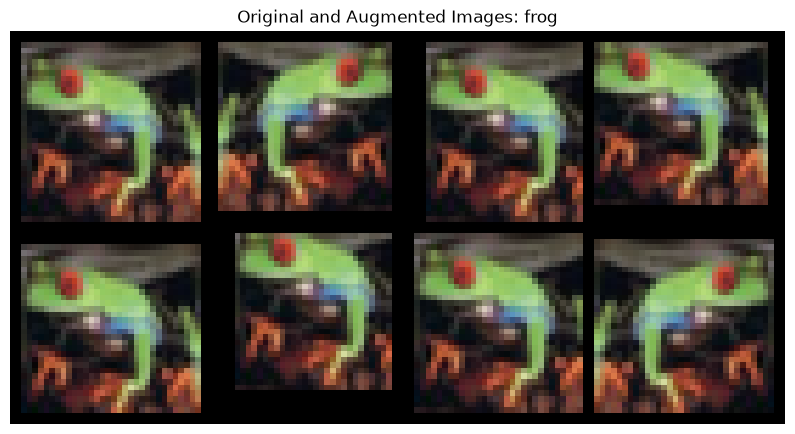

In [11]:
augmentation_grid = make_grid(
    torch.stack(augmented_images),
    nrow=4,
    padding=2
)

plt.figure(figsize=(10, 6))

plt.imshow(
    augmentation_grid.permute(1, 2, 0)
)

plt.title(
    f"Original and Augmented Images: "
    f"{class_names[raw_label]}"
)

plt.axis("off")

plt.show()

### 10) 모델 구성

기본 CNN은 비교를 위해 같은 구조로 다시 만듭니다.

```text
Conv 3→32
→ Pool
→ Conv 32→64
→ Pool
→ Linear 4096→128
→ Linear 128→10
```

In [12]:
def make_basic_cnn():
    return nn.Sequential(
        nn.Conv2d(
            3,
            32,
            kernel_size=3,
            padding=1
        ),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),

        nn.Conv2d(
            32,
            64,
            kernel_size=3,
            padding=1
        ),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),

        nn.Flatten(start_dim=1),
        nn.Linear(
            64 * 8 * 8,
            128
        ),
        nn.ReLU(),
        nn.Linear(
            128,
            10
        )
    )

### 11) 모델 구성

복잡한 사용자 정의 모델 클래스 없이 중첩된 `nn.Sequential`로 구성합니다.

```text
Block1: Conv 2개 → Pool
Block2: Conv 2개 → Pool
Block3: Conv 1개 → Pool
Block4: Conv 1개 → Pool
Block5: Conv 1개 → Pool
분류부: Flatten → Linear → Dropout → Linear
```

각 합성곱은 다음 순서로 구성됩니다.

```text
Conv2d
→ BatchNorm2d
→ ReLU
```

In [13]:
def make_deep_cnn():
    return nn.Sequential(
        # Block 1: 32×32 → 16×16
        nn.Sequential(
            nn.Conv2d(
                3,
                32,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(
                32,
                32,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.10)
        ),

        # Block 2: 16×16 → 8×8
        nn.Sequential(
            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(
                64,
                64,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.15)
        ),

        # Block 3: 8×8 → 4×4
        nn.Sequential(
            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.20)
        ),

        # Block 4: 4×4 → 2×2
        nn.Sequential(
            nn.Conv2d(
                128,
                128,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.25)
        ),

        # Block 5: 2×2 → 1×1
        nn.Sequential(
            nn.Conv2d(
                128,
                256,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.30)
        ),

        nn.Flatten(start_dim=1),
        nn.Linear(256, 128),
        nn.ReLU(),
        nn.Dropout(0.50),
        nn.Linear(128, 10)
    )

### 12) 모델 구조 확인

In [14]:
torch.manual_seed(RANDOM_SEED)

deep_model = make_deep_cnn().to(device)

print(deep_model)

Sequential(
  (0): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout2d(p=0.1, inplace=False)
  )
  (1): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): M

### 13) 모델 파라미터 확인

Deep CNN의 Shape 변화:

```text
입력 [N, 3, 32, 32]
Block1 [N, 32, 16, 16]
Block2 [N, 64, 8, 8]
Block3 [N, 128, 4, 4]
Block4 [N, 128, 2, 2]
Block5 [N, 256, 1, 1]
출력 [N, 10]
```

In [15]:
shape_input = torch.randn(
    2,
    3,
    32,
    32
).to(device)

features = shape_input

print("Input   :", features.shape)

deep_model.eval()

with torch.no_grad():
    for block_index in range(5):
        features = deep_model[
            block_index
        ](features)

        print(
            f"Block{block_index + 1}:",
            features.shape
        )

    shape_logits = deep_model[5:](
        features
    )

print("Logits  :", shape_logits.shape)

basic_parameter_count = sum(
    parameter.numel()
    for parameter in make_basic_cnn().parameters()
)

deep_parameter_count = sum(
    parameter.numel()
    for parameter in deep_model.parameters()
)

print()

print(
    "기본 CNN 파라미터:",
    f"{basic_parameter_count:,}개"
)

print(
    "Deep CNN 파라미터:",
    f"{deep_parameter_count:,}개"
)

Input   : torch.Size([2, 3, 32, 32])
Block1: torch.Size([2, 32, 16, 16])
Block2: torch.Size([2, 64, 8, 8])
Block3: torch.Size([2, 128, 4, 4])
Block4: torch.Size([2, 128, 2, 2])
Block5: torch.Size([2, 256, 1, 1])
Logits  : torch.Size([2, 10])

기본 CNN 파라미터: 545,098개
Deep CNN 파라미터: 617,066개


### 14) Loss 함수와 Optimizer 설정

| 개선 기법 | 역할 |
|---|---|
| 데이터 증강 | 다양한 위치와 방향의 입력 생성 |
| Batch Normalization | 깊은 모델의 학습을 안정화 |
| Dropout2d | 특정 특징맵에 지나치게 의존하는 현상 완화 |
| Dropout | 분류부의 과적합 완화 |
| 학습률 조정기 | 검증 손실이 정체되면 학습률 감소 |
| 조기 종료 | 검증 정확도가 오래 개선되지 않으면 학습 종료 |
| 최고 가중치 복원 | 가장 좋은 검증 성능의 모델 사용 |

개선 기법이 많더라도 결과는 테스트 데이터에서 확인해야 합니다.

학습과 평가 흐름은 과 같습니다.

Deep CNN 내부에 Batch Normalization과 Dropout이 있으므로 `train()`과 `eval()` 구분이 더욱 중요합니다.

In [16]:
loss_function = nn.CrossEntropyLoss()

### 15) 학습 함수 정의

In [17]:
def train_one_epoch(
    model,
    data_loader,
    optimizer
):
    model.train()

    loss_sum = 0.0
    correct = 0
    total = 0

    for images, labels in data_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(images)

        loss = loss_function(
            logits,
            labels
        )

        loss.backward()
        optimizer.step()

        predictions = logits.argmax(
            dim=1
        )

        loss_sum += (
            loss.item()
            * images.size(0)
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    return (
        loss_sum / total,
        correct / total
    )

### 16) 평가 함수 정의

In [18]:
def evaluate_model(
    model,
    data_loader
):
    model.eval()

    loss_sum = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)

            loss = loss_function(
                logits,
                labels
            )

            predictions = logits.argmax(
                dim=1
            )

            loss_sum += (
                loss.item()
                * images.size(0)
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    return (
        loss_sum / total,
        correct / total
    )

### 17) Optimizer 준비

- Optimizer: Adam(아담)
- 시작 학습률: `0.001`
- 검증 손실이 2 Epoch 동안 좋아지지 않으면 학습률을 절반으로 줄임

In [19]:
optimizer = torch.optim.Adam(
    deep_model.parameters(),
    lr=LEARNING_RATE
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

### 18) 학습 기록과 최적 모델 준비

모델 선택 기준:

1. 검증 정확도가 더 높은 Epoch
2. 정확도가 같으면 검증 손실이 더 낮은 Epoch

검증 정확도가 6 Epoch 동안 좋아지지 않으면 학습을 종료합니다.

In [20]:
history = {
    "train_loss": [],
    "train_accuracy": [],
    "validation_loss": [],
    "validation_accuracy": [],
    "learning_rate": []
}

best_validation_accuracy = -1.0

best_validation_loss = float("inf")

best_epoch = 0

best_model_state = copy.deepcopy(
    deep_model.state_dict()
)

epochs_without_improvement = 0

### 19) 모델 학습

In [21]:
for epoch in range(
    1,
    NUMBER_OF_EPOCHS + 1
):
    train_loss, train_accuracy = train_one_epoch(
        deep_model,
        train_loader,
        optimizer
    )

    validation_loss, validation_accuracy = (
        evaluate_model(
            deep_model,
            validation_loader
        )
    )

    is_better = (
        validation_accuracy
        > best_validation_accuracy
        or (
            validation_accuracy
            == best_validation_accuracy
            and validation_loss
            < best_validation_loss
        )
    )

    if is_better:
        best_validation_accuracy = (
            validation_accuracy
        )

        best_validation_loss = (
            validation_loss
        )

        best_epoch = epoch

        best_model_state = copy.deepcopy(
            deep_model.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    scheduler.step(
        validation_loss
    )

    current_learning_rate = optimizer.param_groups[
        0
    ]["lr"]

    history["train_loss"].append(
        train_loss
    )

    history["train_accuracy"].append(
        train_accuracy
    )

    history["validation_loss"].append(
        validation_loss
    )

    history["validation_accuracy"].append(
        validation_accuracy
    )

    history["learning_rate"].append(
        current_learning_rate
    )

    print(
        f"Epoch {epoch:>2d}/{NUMBER_OF_EPOCHS} | "
        f"Train Loss {train_loss:.4f} | "
        f"Train Accuracy {train_accuracy:.4f} | "
        f"Validation Loss {validation_loss:.4f} | "
        f"Validation Accuracy {validation_accuracy:.4f} | "
        f"LR {current_learning_rate:.6f}"
    )

    if (
        epochs_without_improvement
        >= EARLY_STOPPING_PATIENCE
    ):
        print()
        print(
            "조기 종료:",
            f"{EARLY_STOPPING_PATIENCE} Epoch 동안 "
            "검증 정확도가 개선되지 않았습니다."
        )
        break

Epoch  1/30 | Train Loss 1.7711 | Train Accuracy 0.3292 | Validation Loss 1.3216 | Validation Accuracy 0.5220 | LR 0.001000
Epoch  2/30 | Train Loss 1.4243 | Train Accuracy 0.4831 | Validation Loss 1.1291 | Validation Accuracy 0.5882 | LR 0.001000
Epoch  3/30 | Train Loss 1.2698 | Train Accuracy 0.5442 | Validation Loss 0.9791 | Validation Accuracy 0.6462 | LR 0.001000
Epoch  4/30 | Train Loss 1.1559 | Train Accuracy 0.5919 | Validation Loss 0.9047 | Validation Accuracy 0.6692 | LR 0.001000
Epoch  5/30 | Train Loss 1.0788 | Train Accuracy 0.6227 | Validation Loss 0.8307 | Validation Accuracy 0.7004 | LR 0.001000
Epoch  6/30 | Train Loss 1.0224 | Train Accuracy 0.6401 | Validation Loss 0.7668 | Validation Accuracy 0.7188 | LR 0.001000
Epoch  7/30 | Train Loss 0.9762 | Train Accuracy 0.6618 | Validation Loss 0.7554 | Validation Accuracy 0.7220 | LR 0.001000
Epoch  8/30 | Train Loss 0.9344 | Train Accuracy 0.6790 | Validation Loss 0.7232 | Validation Accuracy 0.7424 | LR 0.001000
Epoch  9

### 20) 학습 기록과 최적 모델 준비

In [22]:
deep_model.load_state_dict(
    best_model_state
)

print()

print("최고 검증 Epoch:", best_epoch)

print(
    "최고 검증 정확도:",
    f"{best_validation_accuracy:.4f}"
)


최고 검증 Epoch: 29
최고 검증 정확도: 0.8498


### 21) 학습 Loss 시각화

다음 세 가지를 각각 확인합니다.

- 훈련·검증 손실
- 훈련·검증 정확도
- 학습률 변화

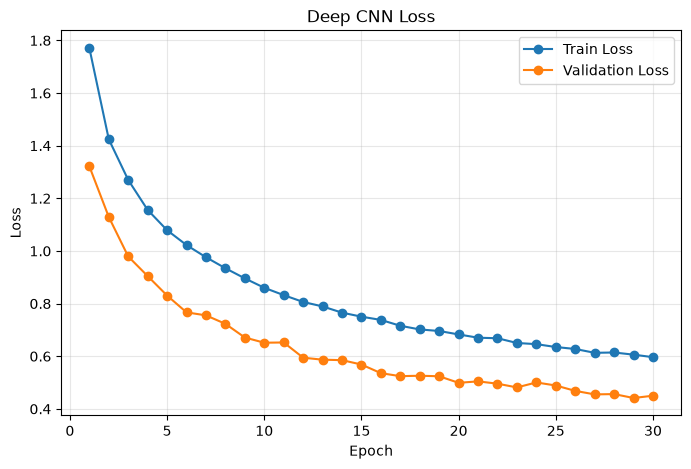

Text(0.5, 1.0, 'Deep CNN Accuracy')

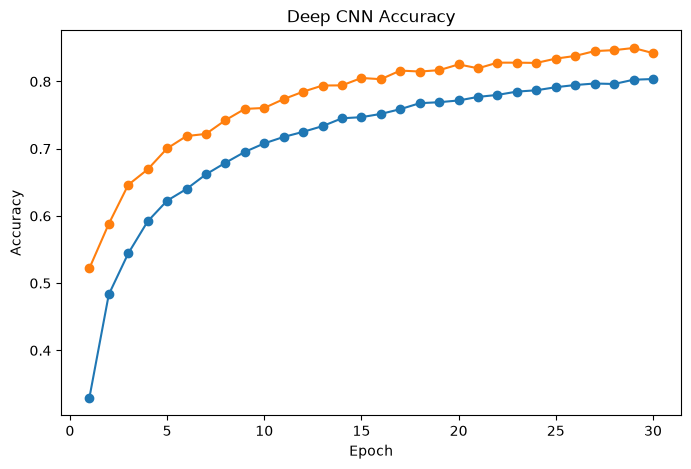

In [23]:
completed_epochs = len(
    history["train_loss"]
)

epoch_numbers = range(
    1,
    completed_epochs + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epoch_numbers,
    history["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    epoch_numbers,
    history["validation_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("Deep CNN Loss")

plt.grid(alpha=0.3)

plt.legend()

plt.show()

plt.figure(figsize=(8, 5))

plt.plot(
    epoch_numbers,
    history["train_accuracy"],
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    epoch_numbers,
    history["validation_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.title("Deep CNN Accuracy")

### 22) 결과 시각화

/tmp/ipykernel_101166/1906487015.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


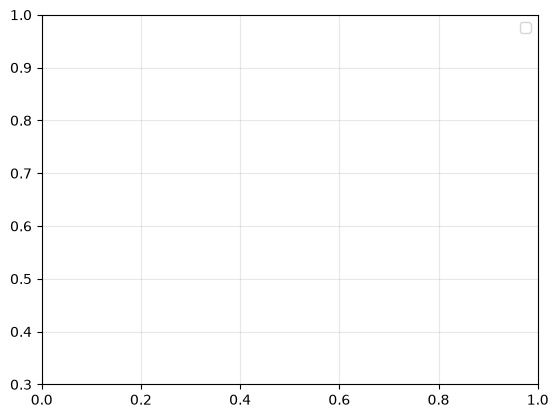

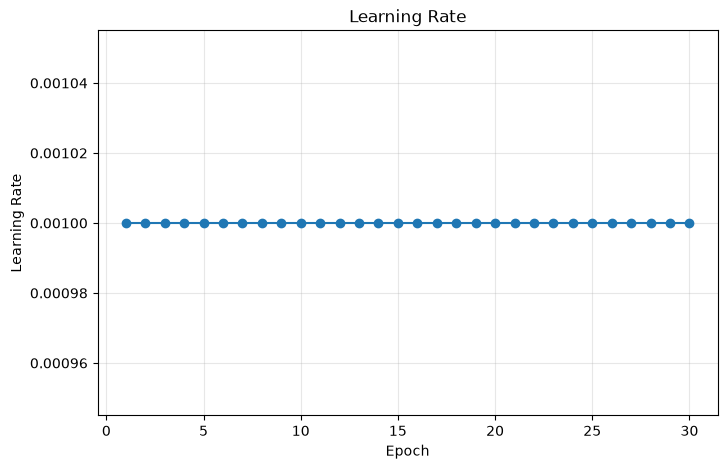

In [24]:
plt.ylim(0.3, 1.0)

plt.grid(alpha=0.3)

plt.legend()

plt.show()

plt.figure(figsize=(8, 5))

plt.plot(
    epoch_numbers,
    history["learning_rate"],
    marker="o"
)

plt.xlabel("Epoch")

plt.ylabel("Learning Rate")

plt.title("Learning Rate")

plt.grid(alpha=0.3)

plt.show()

### 23) 테스트 성능 확인

최고 검증 가중치를 복원한 뒤 테스트 데이터로 한 번 최종 평가합니다.

In [25]:
deep_test_loss, deep_test_accuracy = (
    evaluate_model(
        deep_model,
        test_loader
    )
)

print(
    f"Deep CNN 테스트 손실: "
    f"{deep_test_loss:.4f}"
)

print(
    f"Deep CNN 테스트 정확도: "
    f"{deep_test_accuracy:.4f}"
)

Deep CNN 테스트 손실: 0.4636
Deep CNN 테스트 정확도: 0.8430


### 24) 기본 CNN 체크포인트 준비

비교에 사용할 파일:

```text
ch04_3_best_cifar10_basic_cnn.pt
```

파일이 있으면 같은 테스트 데이터로 기본 CNN을 다시 평가합니다.

파일이 없어도 Deep CNN 학습과 평가는 정상적으로 진행됩니다.

In [26]:
basic_checkpoint_path = MODEL_DIR / "ch04_3_best_cifar10_basic_cnn.pt"

basic_model = None

basic_test_loss = None

basic_test_accuracy = None

### 25) 모델 불러오기

In [27]:
if basic_checkpoint_path.exists():
    basic_checkpoint = torch.load(
        basic_checkpoint_path,
        map_location=device,
        weights_only=True
    )

    basic_model = make_basic_cnn().to(device)

    basic_model.load_state_dict(
        basic_checkpoint[
            "model_state_dict"
        ]
    )

    basic_test_loss, basic_test_accuracy = (
        evaluate_model(
            basic_model,
            test_loader
        )
    )

    print("기본 CNN 복원 완료")
    print(
        f"기본 CNN 테스트 손실: "
        f"{basic_test_loss:.4f}"
    )
    print(
        f"기본 CNN 테스트 정확도: "
        f"{basic_test_accuracy:.4f}"
    )

else:
    print(
        "기본 CNN 파일이 없어 "
        "모델 간 비교를 생략합니다."
    )

기본 CNN 복원 완료
기본 CNN 테스트 손실: 1.1079
기본 CNN 테스트 정확도: 0.7109


### 26) 테스트 성능 확인

비교 항목:

- 합성곱 계층 수
- 파라미터 수
- 테스트 손실
- 테스트 정확도
- 정확도 변화

Deep CNN이 항상 더 좋은 결과를 보장하지는 않습니다.
실제 테스트 결과를 기준으로 판단합니다.

In [28]:
print("===== 모델 비교 =====")

print(
    "기본 CNN 파라미터:",
    f"{basic_parameter_count:,}개"
)

print(
    "Deep CNN 파라미터:",
    f"{deep_parameter_count:,}개"
)

print(
    "Deep CNN 테스트 손실:",
    f"{deep_test_loss:.4f}"
)

print(
    "Deep CNN 테스트 정확도:",
    f"{deep_test_accuracy:.4f}"
)

===== 모델 비교 =====
기본 CNN 파라미터: 545,098개
Deep CNN 파라미터: 617,066개
Deep CNN 테스트 손실: 0.4636
Deep CNN 테스트 정확도: 0.8430


### 27) 테스트 성능 확인

기본 CNN 테스트 손실: 1.1079
기본 CNN 테스트 정확도: 0.7109
정확도 변화: +0.1321


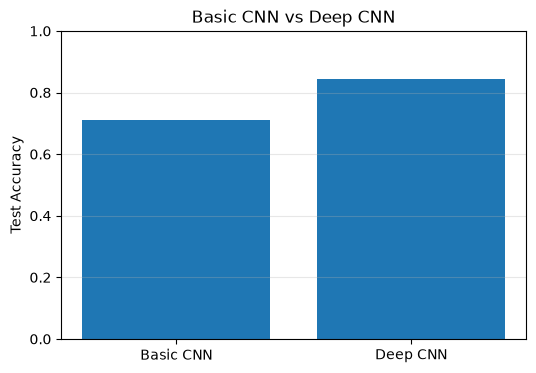

In [29]:
if basic_test_accuracy is not None:
    accuracy_change = (
        deep_test_accuracy
        - basic_test_accuracy
    )

    print(
        "기본 CNN 테스트 손실:",
        f"{basic_test_loss:.4f}"
    )

    print(
        "기본 CNN 테스트 정확도:",
        f"{basic_test_accuracy:.4f}"
    )

    print(
        "정확도 변화:",
        f"{accuracy_change:+.4f}"
    )

    plt.figure(figsize=(6, 4))

    plt.bar(
        ["Basic CNN", "Deep CNN"],
        [
            basic_test_accuracy,
            deep_test_accuracy
        ]
    )

    plt.ylabel("Test Accuracy")
    plt.title("Basic CNN vs Deep CNN")
    plt.ylim(0, 1)
    plt.grid(
        axis="y",
        alpha=0.3
    )
    plt.show()

### 28) 예측 결과 수집 함수

혼동행렬과 오답 비교에서 모델을 반복 실행하지 않도록 테스트 결과를 한 번에 모읍니다.

In [30]:
def collect_predictions(
    model,
    data_loader
):
    model.eval()

    image_batches = []
    label_batches = []
    prediction_batches = []

    with torch.no_grad():
        for images, labels in data_loader:
            logits = model(
                images.to(device)
            )

            predictions = logits.argmax(
                dim=1
            ).cpu()

            image_batches.append(images)
            label_batches.append(labels)
            prediction_batches.append(
                predictions
            )

    return (
        torch.cat(image_batches),
        torch.cat(label_batches),
        torch.cat(prediction_batches)
    )

### 29) 예측 결과 수집

In [31]:
deep_images, deep_labels, deep_predictions = (
    collect_predictions(
        deep_model,
        test_loader
    )
)

print(
    "Deep CNN 예측 수:",
    len(deep_predictions)
)

Deep CNN 예측 수: 10000


### 30) Confusion Matrix 준비

```text
행: 실제 클래스
열: 예측 클래스
대각선: 정답
대각선 밖: 오답
```

In [32]:
deep_confusion_matrix = torch.zeros(
    10,
    10,
    dtype=torch.int64
)

### 31) Confusion Matrix 계산

In [33]:
for actual, predicted in zip(
    deep_labels,
    deep_predictions
):
    deep_confusion_matrix[
        actual,
        predicted
    ] += 1

### 32) Confusion Matrix 시각화

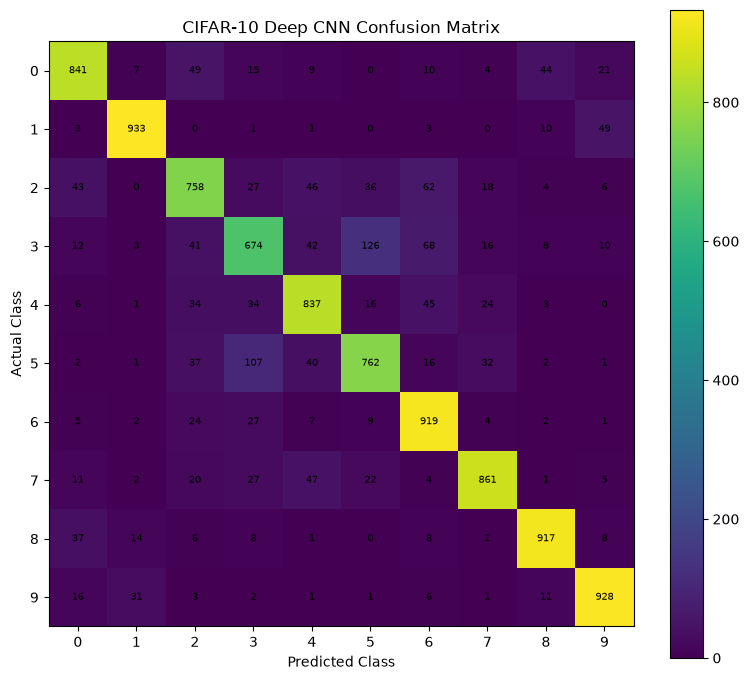

In [34]:
plt.figure(figsize=(8, 7))

plt.imshow(
    deep_confusion_matrix.numpy()
)

plt.xticks(range(10))

plt.yticks(range(10))

plt.xlabel("Predicted Class")

plt.ylabel("Actual Class")

plt.title("CIFAR-10 Deep CNN Confusion Matrix")

for row in range(10):
    for column in range(10):
        plt.text(
            column,
            row,
            int(
                deep_confusion_matrix[
                    row,
                    column
                ]
            ),
            ha="center",
            va="center",
            fontsize=7
        )

plt.colorbar()

plt.tight_layout()

plt.show()

### 33) 클래스별 정확도 확인

Deep CNN의 클래스별 정확도를 계산합니다.

기본 CNN이 있으면 같은 그래프에서 비교합니다.

In [35]:
deep_class_correct = (
    deep_confusion_matrix.diag()
)

deep_class_total = (
    deep_confusion_matrix.sum(dim=1)
)

deep_class_accuracy = (
    deep_class_correct.float()
    / deep_class_total
)

print("===== Deep CNN 클래스별 정확도 =====")

===== Deep CNN 클래스별 정확도 =====


### 34) 클래스별 정확도 확인

In [36]:
for class_index in range(10):
    print(
        f"{class_index}: "
        f"{class_names_ko[class_index]:<4} | "
        f"{deep_class_accuracy[class_index].item():.4f}"
    )

0: 비행기  | 0.8410
1: 자동차  | 0.9330
2: 새    | 0.7580
3: 고양이  | 0.6740
4: 사슴   | 0.8370
5: 개    | 0.7620
6: 개구리  | 0.9190
7: 말    | 0.8610
8: 배    | 0.9170
9: 트럭   | 0.9280


### 35) Confusion Matrix 준비

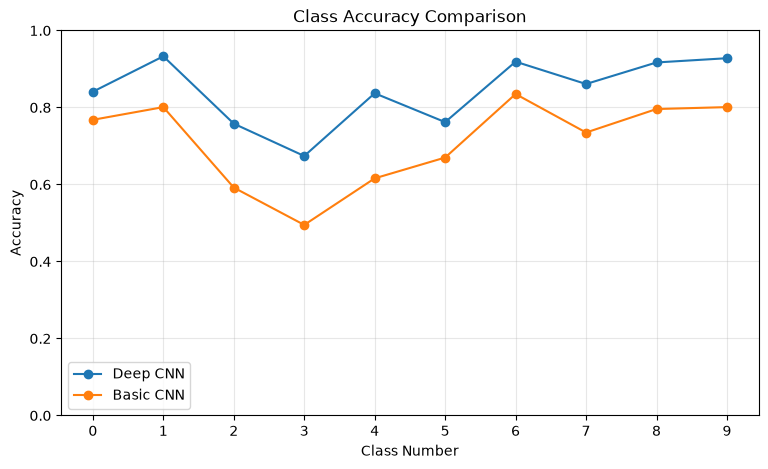

In [37]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(10),
    deep_class_accuracy.numpy(),
    marker="o",
    label="Deep CNN"
)

if basic_model is not None:
    (
        basic_images,
        basic_labels,
        basic_predictions
    ) = collect_predictions(
        basic_model,
        test_loader
    )

    basic_confusion_matrix = torch.zeros(
        10,
        10,
        dtype=torch.int64
    )

    for actual, predicted in zip(
        basic_labels,
        basic_predictions
    ):
        basic_confusion_matrix[
            actual,
            predicted
        ] += 1

    basic_class_accuracy = (
        basic_confusion_matrix.diag().float()
        / basic_confusion_matrix.sum(dim=1)
    )

    plt.plot(
        range(10),
        basic_class_accuracy.numpy(),
        marker="o",
        label="Basic CNN"
    )

plt.xticks(range(10))

plt.ylim(0, 1)

plt.xlabel("Class Number")

plt.ylabel("Accuracy")

plt.title("Class Accuracy Comparison")

plt.grid(alpha=0.3)

plt.legend()

plt.show()

### 36) 결과 시각화

기본 CNN이 틀렸지만 Deep CNN이 맞힌 이미지를 확인합니다.

이미지 아래의 번호와 출력된 설명을 함께 확인합니다.

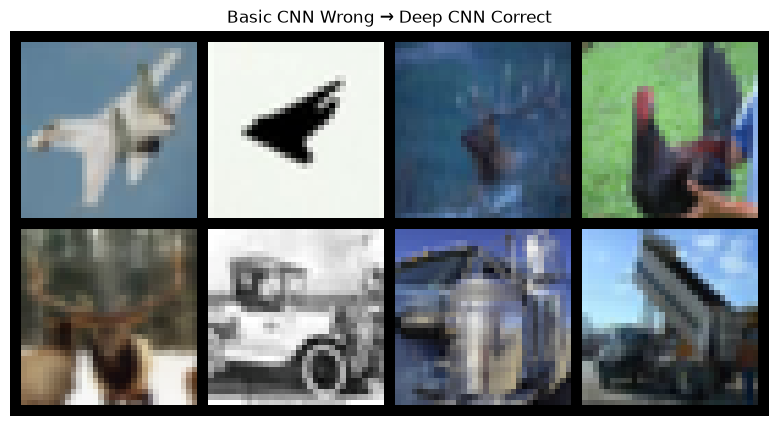

기본 CNN 오답·Deep CNN 정답: 1790 개
0: 실제 비행기 | 기본 개 | Deep 비행기
1: 실제 비행기 | 기본 새 | Deep 비행기
2: 실제 사슴 | 기본 비행기 | Deep 사슴
3: 실제 새 | 기본 사슴 | Deep 새
4: 실제 사슴 | 기본 새 | Deep 사슴
5: 실제 자동차 | 기본 트럭 | Deep 자동차
6: 실제 트럭 | 기본 고양이 | Deep 트럭
7: 실제 트럭 | 기본 말 | Deep 트럭


In [38]:
if basic_model is not None:
    improved_indices = torch.where(
        (basic_predictions != basic_labels)
        & (deep_predictions == deep_labels)
    )[0]

    example_count = min(
        8,
        len(improved_indices)
    )

    improved_images = torch.stack(
        [
            denormalize_image(
                deep_images[index]
            )
            for index in improved_indices[
                :example_count
            ]
        ]
    )

    improved_grid = make_grid(
        improved_images,
        nrow=4,
        padding=2
    )

    plt.figure(figsize=(10, 5))
    plt.imshow(
        improved_grid.permute(1, 2, 0)
    )
    plt.title(
        "Basic CNN Wrong → Deep CNN Correct"
    )
    plt.axis("off")
    plt.show()

    print(
        "기본 CNN 오답·Deep CNN 정답:",
        len(improved_indices),
        "개"
    )

    for display_index, data_index in enumerate(
        improved_indices[:example_count]
    ):
        true_label = deep_labels[
            data_index
        ].item()

        basic_label = basic_predictions[
            data_index
        ].item()

        deep_label = deep_predictions[
            data_index
        ].item()

        print(
            f"{display_index}: "
            f"실제 {class_names_ko[true_label]} | "
            f"기본 {class_names_ko[basic_label]} | "
            f"Deep {class_names_ko[deep_label]}"
        )

else:
    print(
        "기본 CNN이 없어 개선 사례를 생략합니다."
    )

### 37) 오분류 데이터 확인

모델을 깊게 만들어도 다음과 같은 이미지는 어려울 수 있습니다.

- 물체가 작음
- 배경이 복잡함
- 물체 일부만 보임
- 클래스의 모양이 비슷함
- 32×32 해상도가 낮음

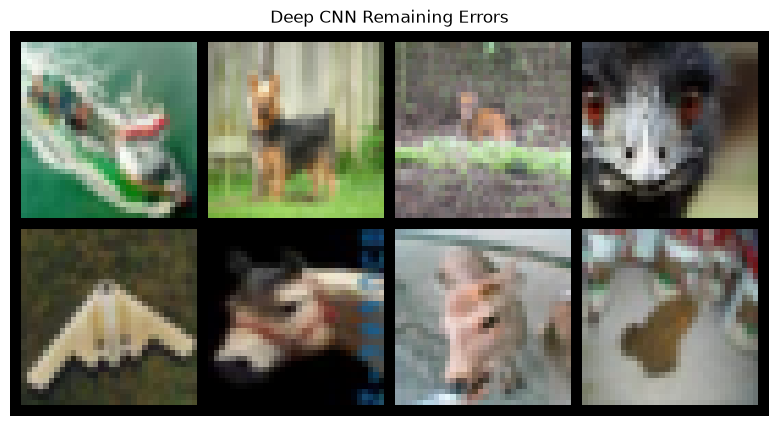

Deep CNN 전체 오답: 1570 개


In [39]:
deep_wrong_indices = torch.where(
    deep_predictions != deep_labels
)[0]

wrong_example_count = min(
    8,
    len(deep_wrong_indices)
)

deep_wrong_images = torch.stack(
    [
        denormalize_image(
            deep_images[index]
        )
        for index in deep_wrong_indices[
            :wrong_example_count
        ]
    ]
)

deep_wrong_grid = make_grid(
    deep_wrong_images,
    nrow=4,
    padding=2
)

plt.figure(figsize=(10, 5))

plt.imshow(
    deep_wrong_grid.permute(1, 2, 0)
)

plt.title("Deep CNN Remaining Errors")

plt.axis("off")

plt.show()

print(
    "Deep CNN 전체 오답:",
    len(deep_wrong_indices),
    "개"
)

### 38) 오분류 데이터 확인

In [40]:
for display_index, data_index in enumerate(
    deep_wrong_indices[:wrong_example_count]
):
    true_label = deep_labels[
        data_index
    ].item()

    predicted_label = deep_predictions[
        data_index
    ].item()

    print(
        f"{display_index}: "
        f"실제 {class_names_ko[true_label]} "
        f"→ 예측 {class_names_ko[predicted_label]}"
    )

0: 실제 배 → 예측 개구리
1: 실제 개 → 예측 사슴
2: 실제 사슴 → 예측 개구리
3: 실제 새 → 예측 배
4: 실제 비행기 → 예측 트럭
5: 실제 말 → 예측 고양이
6: 실제 사슴 → 예측 개
7: 실제 개구리 → 예측 고양이


### 39) 주요 오분류 확인

혼동행렬의 대각선을 제외하고 가장 큰 값을 찾습니다.

방향을 구분합니다.

```text
실제 고양이 → 예측 개
```

위 관계와 `실제 개 → 예측 고양이`는 서로 다른 오류입니다.

In [41]:
wrong_confusion = (
    deep_confusion_matrix.clone()
)

wrong_confusion.fill_diagonal_(0)

flat_index = wrong_confusion.argmax().item()

confused_actual = (
    flat_index // 10
)

confused_predicted = (
    flat_index % 10
)

confused_count = wrong_confusion[
    confused_actual,
    confused_predicted
].item()

print(
    f"실제 {class_names_ko[confused_actual]} "
    f"→ 예측 {class_names_ko[confused_predicted]}: "
    f"{confused_count}개"
)

실제 고양이 → 예측 개: 126개


### 40) 모델 저장

Checkpoint에는 다음 내용을 저장합니다.

- Deep CNN 가중치
- 합성곱 채널 수
- 데이터 정규화 값
- 클래스 이름
- 최고 검증 성능
- 테스트 성능
- 실제 완료 Epoch

In [42]:
deep_checkpoint_path = MODEL_DIR / "ch04_4_best_cifar10_deep_cnn.pt"

deep_checkpoint = {
    "model_name": "CIFAR-10 Deep CNN",
    "model_state_dict": deep_model.state_dict(),
    "input_channels": 3,
    "feature_channels": [
        32,
        32,
        64,
        64,
        128,
        128,
        256
    ],
    "image_size": [3, 32, 32],
    "number_of_classes": 10,
    "class_names": class_names,
    "class_names_ko": class_names_ko,
    "normalization_mean": list(CIFAR10_MEAN),
    "normalization_std": list(CIFAR10_STD),
    "best_epoch": best_epoch,
    "completed_epochs": completed_epochs,
    "validation_loss": best_validation_loss,
    "validation_accuracy": best_validation_accuracy,
    "test_loss": deep_test_loss,
    "test_accuracy": deep_test_accuracy
}

torch.save(
    deep_checkpoint,
    deep_checkpoint_path
)

loaded_checkpoint = torch.load(
    deep_checkpoint_path,
    map_location="cpu",
    weights_only=True
)

restored_deep_model = make_deep_cnn()

restored_deep_model.load_state_dict(
    loaded_checkpoint[
        "model_state_dict"
    ]
)

<All keys matched successfully>

### 41) 테스트 성능 확인

In [43]:
restored_deep_model.eval()

print("저장 파일:", deep_checkpoint_path)

print(
    "저장된 테스트 정확도:",
    f"{loaded_checkpoint['test_accuracy']:.4f}"
)

저장 파일: models/ch05_4_best_cifar10_deep_cnn.pt
저장된 테스트 정확도: 0.8430
